In [1]:
# Cell kiểm tra — chạy trong notebook
import tensorflow as tf
import imblearn
import sklearn

print(f"TensorFlow    : {tf.__version__}")
print(f"imbalanced-learn : {imblearn.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"\nGPU available : {tf.config.list_physical_devices('GPU')}")

TensorFlow    : 2.21.0
imbalanced-learn : 0.14.2
scikit-learn  : 1.8.0

GPU available : []


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

ROOT         = Path(r"D:\hocki7\Data Annalyst\Detai")
PATH_CLEANED = ROOT / "1_data" / "processed" / "03_cleaned.csv"
PATH_MODEL   = ROOT / "1_data" / "processed"
FIG_DIR      = ROOT / "5_reports" / "figures"

df = pd.read_csv(PATH_CLEANED)
print(f"✅ Load xong: {df.shape[0]:,} dòng | {df.shape[1]} cột")
print(f"\nCác cột hiện có:")
print(df.columns.tolist())

✅ Load xong: 200,000 dòng | 25 cột

Các cột hiện có:
['isFraud', 'TransactionAmt_log', 'ProductCD_enc', 'card1', 'card4_enc', 'card6_enc', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain_enc', 'R_emaildomain_enc', 'C1', 'C2', 'C6', 'C_total', 'D1', 'D4', 'D10', 'D_total', 'hour_of_day', 'day_of_week', 'is_night', 'M4_enc', 'M6_enc']


In [3]:
# Theo insight EDA: bỏ các cột gây đa cộng tuyến
COLS_DROP_MULTICOLLINEAR = ['C1', 'C2', 'C6', 'D1', 'D4']

df_model = df.drop(columns=COLS_DROP_MULTICOLLINEAR)

print(f"✅ Bỏ {len(COLS_DROP_MULTICOLLINEAR)} cột đa cộng tuyến")
print(f"   Còn lại: {df_model.shape[1]} cột")
print(f"\nDanh sách cột dùng cho model:")
for i, col in enumerate(df_model.columns, 1):
    print(f"  {i:2}. {col}")

✅ Bỏ 5 cột đa cộng tuyến
   Còn lại: 20 cột

Danh sách cột dùng cho model:
   1. isFraud
   2. TransactionAmt_log
   3. ProductCD_enc
   4. card1
   5. card4_enc
   6. card6_enc
   7. addr1
   8. addr2
   9. dist1
  10. dist2
  11. P_emaildomain_enc
  12. R_emaildomain_enc
  13. C_total
  14. D10
  15. D_total
  16. hour_of_day
  17. day_of_week
  18. is_night
  19. M4_enc
  20. M6_enc


In [4]:
# Vấn đề: các cột "_enc" hiện tại là Label Encoding (0,1,2,3...)
# Logistic Regression & Neural Network sẽ HIỂU SAI thứ tự này
# (model nghĩ card4_enc=2 "lớn hơn" card4_enc=1 — không đúng ý nghĩa)
# → Cần đổi các cột categorical gốc sang One-Hot Encoding

# Random Forest thì KHÔNG bị ảnh hưởng bởi vấn đề này (cây quyết định
# tách theo ngưỡng, không quan tâm thứ tự số) — nhưng để dùng CHUNG
# 1 bộ dữ liệu cho cả 3 mô hình, ta One-Hot hết cho công bằng và nhất quán

COLS_CATEGORICAL = [
    'ProductCD_enc', 'card4_enc', 'card6_enc',
    'P_emaildomain_enc', 'R_emaildomain_enc',
    'M4_enc', 'M6_enc'
]

# Kiểm tra số lượng giá trị unique mỗi cột — quyết định One-Hot có hợp lý không
print("Kiểm tra số lượng unique values (quyết định có nên One-Hot không):")
print(f"{'Cột':<22} {'Unique':>8}   Đánh giá")
print("-" * 55)
for col in COLS_CATEGORICAL:
    if col in df_model.columns:
        n = df_model[col].nunique()
        eval_text = "✅ Phù hợp One-Hot" if n <= 15 else "⚠️ Nhiều giá trị — cân nhắc"
        print(f"  {col:<20} {n:>8}   {eval_text}")

Kiểm tra số lượng unique values (quyết định có nên One-Hot không):
Cột                      Unique   Đánh giá
-------------------------------------------------------
  ProductCD_enc               5   ✅ Phù hợp One-Hot
  card4_enc                   5   ✅ Phù hợp One-Hot
  card6_enc                   5   ✅ Phù hợp One-Hot
  P_emaildomain_enc          10   ✅ Phù hợp One-Hot
  R_emaildomain_enc          10   ✅ Phù hợp One-Hot
  M4_enc                      4   ✅ Phù hợp One-Hot
  M6_enc                      3   ✅ Phù hợp One-Hot


In [5]:
# pd.get_dummies thực hiện One-Hot Encoding
# drop_first=True: bỏ 1 cột để tránh đa cộng tuyến hoàn hảo (dummy variable trap)

COLS_TO_ONEHOT = [c for c in COLS_CATEGORICAL if c in df_model.columns]

print(f"Số cột trước One-Hot: {df_model.shape[1]}")

df_onehot = pd.get_dummies(
    df_model,
    columns=COLS_TO_ONEHOT,
    drop_first=True,
    prefix=COLS_TO_ONEHOT
)

# Chuyển cột bool (True/False) thành 0/1 — một số thư viện yêu cầu kiểu số
bool_cols = df_onehot.select_dtypes(include='bool').columns
df_onehot[bool_cols] = df_onehot[bool_cols].astype(int)

print(f"Số cột sau One-Hot : {df_onehot.shape[1]}")
print(f"\n→ Tăng thêm {df_onehot.shape[1] - df_model.shape[1]} cột do One-Hot Encoding")
print(f"\nDanh sách cột mới sinh ra (ví dụ 10 cột đầu):")
new_cols = [c for c in df_onehot.columns if c not in df_model.columns]
print(new_cols[:10])

Số cột trước One-Hot: 20
Số cột sau One-Hot : 48

→ Tăng thêm 28 cột do One-Hot Encoding

Danh sách cột mới sinh ra (ví dụ 10 cột đầu):
['ProductCD_enc_1', 'ProductCD_enc_2', 'ProductCD_enc_3', 'ProductCD_enc_4', 'card4_enc_1', 'card4_enc_2', 'card4_enc_3', 'card4_enc_4', 'card6_enc_1', 'card6_enc_2']


In [6]:
# Chia 2 lần để ra 3 tập:
# Lần 1: Tách Test (15%) ra trước
# Lần 2: Tách phần còn lại thành Train (70%) và Validation (15%)

X = df_onehot.drop(columns=['isFraud'])
y = df_onehot['isFraud']

# Lần 1: 85% (train+val) vs 15% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Lần 2: chia tiếp 85% đó thành train (70% tổng) và val (15% tổng)
# 0.15 / 0.85 ≈ 0.1765 để val chiếm đúng 15% của TOÀN BỘ dữ liệu gốc
val_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio, random_state=42, stratify=y_temp
)

print("✅ Chia dữ liệu thành 3 tập:")
print(f"   Train      : {X_train.shape[0]:,} dòng ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   Validation : {X_val.shape[0]:,} dòng ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"   Test       : {X_test.shape[0]:,} dòng ({X_test.shape[0]/len(X)*100:.1f}%)")

print(f"\n📊 Kiểm tra tỷ lệ fraud đồng đều giữa 3 tập (quan trọng!):")
print(f"   Train      : {y_train.mean()*100:.2f}% fraud")
print(f"   Validation : {y_val.mean()*100:.2f}% fraud")
print(f"   Test       : {y_test.mean()*100:.2f}% fraud")
print(f"   → 3 tỷ lệ này phải gần bằng nhau nhờ stratify")

✅ Chia dữ liệu thành 3 tập:
   Train      : 139,999 dòng (70.0%)
   Validation : 30,001 dòng (15.0%)
   Test       : 30,000 dòng (15.0%)

📊 Kiểm tra tỷ lệ fraud đồng đều giữa 3 tập (quan trọng!):
   Train      : 10.33% fraud
   Validation : 10.33% fraud
   Test       : 10.33% fraud
   → 3 tỷ lệ này phải gần bằng nhau nhờ stratify


In [8]:
# QUAN TRỌNG: fit() CHỈ trên Train, sau đó transform() cho Val và Test
# Nếu fit cả trên Val/Test → bị "data leakage" (rò rỉ thông tin), 
# kết quả đánh giá sẽ bị ảo, không phản ánh đúng khả năng thực tế

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # fit + transform
X_val_scaled   = scaler.transform(X_val)          # chỉ transform
X_test_scaled  = scaler.transform(X_test)          # chỉ transform

# Chuyển lại thành DataFrame để dễ debug và lưu file
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_val_scaled   = pd.DataFrame(X_val_scaled,   columns=X_val.columns,   index=X_val.index)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=X_test.columns,  index=X_test.index)

print("✅ Scale dữ liệu xong (StandardScaler)")
print(f"   Train sau scale : mean≈{X_train_scaled.values.mean():.4f}, std≈{X_train_scaled.values.std():.4f}")
print(f"\n⚠️ Scaler chỉ fit() trên Train — Val và Test chỉ transform()")
print(f"   Dùng X_train_scaled cho: Logistic Regression, Neural Network")
print(f"   Dùng X_train (chưa scale) cho: Random Forest (cây không cần scale)")

✅ Scale dữ liệu xong (StandardScaler)
   Train sau scale : mean≈-0.0000, std≈1.0000

⚠️ Scaler chỉ fit() trên Train — Val và Test chỉ transform()
   Dùng X_train_scaled cho: Logistic Regression, Neural Network
   Dùng X_train (chưa scale) cho: Random Forest (cây không cần scale)


Trước SMOTE:
  Train — Không fraud: 125,535 | Fraud: 14,464

Sau SMOTE:
  Train — Không fraud: 125,535 | Fraud: 125,535
  → Đã cân bằng 50/50


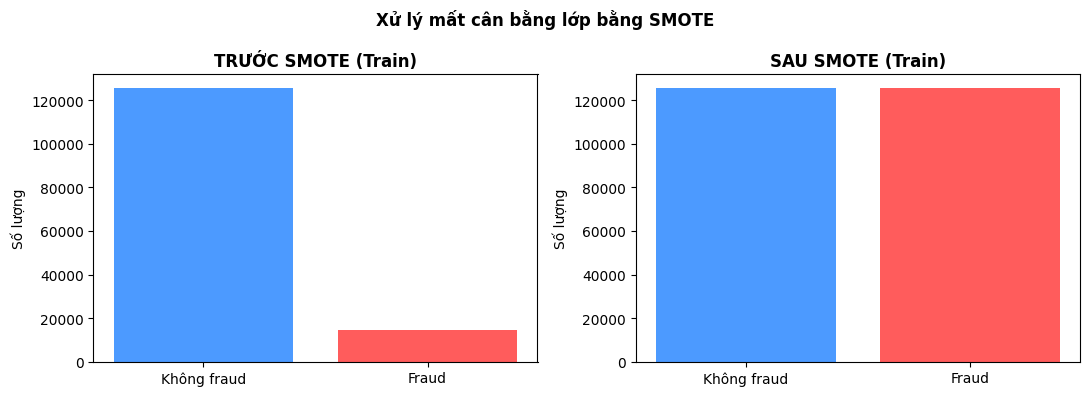


💡 Lưu ý: SMOTE chỉ là 1 trong các lựa chọn. Khi train model,
   ta sẽ SO SÁNH cả 2 cách:
   (a) Dùng class_weight='balanced' (không cần SMOTE)
   (b) Dùng SMOTE + train bình thường
   → Để xem cách nào cho kết quả tốt hơn trên tập Test thật


In [9]:
# QUY TẮC VÀNG: SMOTE chỉ áp dụng trên TRAIN
# Val và Test PHẢI giữ nguyên phân phối thật (để đánh giá đúng thực tế)
# Nếu SMOTE cả Val/Test → đánh giá mô hình trên dữ liệu "giả", không có ý nghĩa

print("Trước SMOTE:")
print(f"  Train — Không fraud: {(y_train==0).sum():,} | Fraud: {(y_train==1).sum():,}")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"\nSau SMOTE:")
print(f"  Train — Không fraud: {(y_train_smote==0).sum():,} | Fraud: {(y_train_smote==1).sum():,}")
print(f"  → Đã cân bằng 50/50")

# Biểu đồ minh họa trước/sau SMOTE
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(['Không fraud', 'Fraud'],
            [(y_train==0).sum(), (y_train==1).sum()],
            color=['#4C9AFF', '#FF5C5C'])
axes[0].set_title('TRƯỚC SMOTE (Train)', fontweight='bold')
axes[0].set_ylabel('Số lượng')

axes[1].bar(['Không fraud', 'Fraud'],
            [(y_train_smote==0).sum(), (y_train_smote==1).sum()],
            color=['#4C9AFF', '#FF5C5C'])
axes[1].set_title('SAU SMOTE (Train)', fontweight='bold')
axes[1].set_ylabel('Số lượng')

plt.suptitle('Xử lý mất cân bằng lớp bằng SMOTE', fontweight='bold')
plt.tight_layout()
plt.savefig(str(FIG_DIR / "06_smote_balance.png"), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n💡 Lưu ý: SMOTE chỉ là 1 trong các lựa chọn. Khi train model,")
print(f"   ta sẽ SO SÁNH cả 2 cách:")
print(f"   (a) Dùng class_weight='balanced' (không cần SMOTE)")
print(f"   (b) Dùng SMOTE + train bình thường")
print(f"   → Để xem cách nào cho kết quả tốt hơn trên tập Test thật")

In [10]:
# Lưu riêng từng phần để dùng lại ở notebook Modeling
# Không cần chạy lại pipeline tiền xử lý mỗi lần train model

import joblib

# Lưu các tập dữ liệu (dùng chung cho Random Forest — không scale)
X_train.to_csv(PATH_MODEL / "X_train.csv", index=False)
X_val.to_csv(PATH_MODEL / "X_val.csv", index=False)
X_test.to_csv(PATH_MODEL / "X_test.csv", index=False)
y_train.to_csv(PATH_MODEL / "y_train.csv", index=False)
y_val.to_csv(PATH_MODEL / "y_val.csv", index=False)
y_test.to_csv(PATH_MODEL / "y_test.csv", index=False)

# Lưu bản đã scale (dùng cho Logistic Regression, Neural Network)
X_train_scaled.to_csv(PATH_MODEL / "X_train_scaled.csv", index=False)
X_val_scaled.to_csv(PATH_MODEL / "X_val_scaled.csv", index=False)
X_test_scaled.to_csv(PATH_MODEL / "X_test_scaled.csv", index=False)

# Lưu bản đã SMOTE (dùng thử nghiệm so sánh)
X_train_smote.to_csv(PATH_MODEL / "X_train_smote.csv", index=False)
pd.Series(y_train_smote, name='isFraud').to_csv(PATH_MODEL / "y_train_smote.csv", index=False)

# Lưu scaler để dùng lại sau này (ví dụ khi deploy API)
joblib.dump(scaler, ROOT / "4_models" / "scaler.pkl")

print("✅ Đã lưu toàn bộ các tập dữ liệu:")
print(f"""
   Bản GỐC (cho Random Forest):
     X_train.csv, X_val.csv, X_test.csv
     y_train.csv, y_val.csv, y_test.csv

   Bản SCALED (cho Logistic Regression, Neural Network):
     X_train_scaled.csv, X_val_scaled.csv, X_test_scaled.csv

   Bản SMOTE (thử nghiệm so sánh):
     X_train_smote.csv, y_train_smote.csv

   Scaler đã fit:
     4_models/scaler.pkl
""")
print(f"🎉 SẴN SÀNG cho Giai đoạn 4 — Train 3 mô hình!")

✅ Đã lưu toàn bộ các tập dữ liệu:

   Bản GỐC (cho Random Forest):
     X_train.csv, X_val.csv, X_test.csv
     y_train.csv, y_val.csv, y_test.csv

   Bản SCALED (cho Logistic Regression, Neural Network):
     X_train_scaled.csv, X_val_scaled.csv, X_test_scaled.csv

   Bản SMOTE (thử nghiệm so sánh):
     X_train_smote.csv, y_train_smote.csv

   Scaler đã fit:
     4_models/scaler.pkl

🎉 SẴN SÀNG cho Giai đoạn 4 — Train 3 mô hình!
